More information on how to use this notebook is available in the `README.md`.

## 0. Packages

Check that the packages the notebook needs are installed. The cell installs any missing ones with pip in the environment of the notebook, and then imports everything.

In [18]:
import importlib.util
import subprocess
import sys

# Packages needed by the notebook. We use a dictionnary because the name used in `import` can differ from the name used by pip (e.g. Pillow)
REQUIRED = {
    "numpy": "numpy",
    "PIL": "pillow",
    "matplotlib": "matplotlib",
    "torch": "torch",
    "transformers": "transformers",
    "accelerate": "accelerate",
}

missing = [pip_name for module, pip_name in REQUIRED.items() if importlib.util.find_spec(module) is None] # find_spec gives None when the module cannot be found
if missing:
    print("Installing the missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing]) # sys.executable = the python of this notebook, so the packages land in the right environment
else:
    print("All the required packages are already installed")

import json
import shutil
from pathlib import Path

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

All the required packages are already installed


## Config

Everything that changes from one run to another is in this cell: the dataset, the depth model and what to display. The algorithm constants below are the same for every dataset. The only things that depend on the dataset are in `PARAMS` (see above for details).
Choose the model size in this cell. Depth Anything V2 (relative depth) comes in three sizes: `small`, `base` and `large`. A bigger model is slower but should give a sharper depth.

In [ ]:
MODELS = {
    "small": "depth-anything/Depth-Anything-V2-Small-hf",
    "base":  "depth-anything/Depth-Anything-V2-Base-hf",
    "large": "depth-anything/Depth-Anything-V2-Large-hf",
}


DATASET = "bdd100k" # name of the folder in data/, it also needs an entry in PARAMS below
MODEL = "small" # depth model to use, one of the keys of MODELS above

# frames to look at in section 6 (file names without extension), for example ["001100", "001260"]. Empty = display nothing
# SHOW_FRAMES = ["001100", "001152", "001173", "001260", "001362"] # tartandrive_2
SHOW_FRAMES = ["b1c9c847-3bda4659", "b1cac6a7-04e33135", "b1ceb32e-51852abe", "b1d0091f-f2c2d2ae", "b1d10d08-c35503b8"] # bdd100k

RECOMPUTE_DEPTH = False # True = compute the depth of every frame again, even if it is already saved
MAKE_ZIP = True # True = zip the maps at the end

# Dataset params (see the introduction for more details)
PARAMS = {
    "bdd100k":       {"b": 20, "shape": (720, 1280)},
    "rellis":        {"b": 20, "shape": None},
    "tartandrive":   {"b": 1,  "shape": (544, 1024)},
    "tartandrive_2": {"b": 1,  "shape": (544, 1024)},
}

# Constants. These values were found through experimentation in other notebooks.
lo, hi = 0.0, 0.3 # ends of the cost ramp: residual <= lo gives cost 0, residual >= hi gives cost 1
FIT_TOP = 0.6 # the ground line is fitted only on the rows below this fraction of the image height
Q_FIT = 0.3 # for each row, the quantile over all columns taken as the ground value (0.5 would be the median)

HOOD_TOP = 0.7 # the hood is only searched below this fraction of the image height
HOOD_COLS = (0.25, 0.5, 0.75) # columns used to look for the hood, as fractions of the image width. This helps in case of a smaller or slanted hood.
HOOD_MIN_AGREE = 2 # number of columns that must find an edge to say there is a hood
HOOD_JUMP = 0.07 # smallest jump in inverse depth that counts as the edge of the hood
HOOD_K = 5 # rows averaged on each side of a boundary, to ignore single-row noise

R0_TOL = 0.1 # tolerance used to find r0 = how far from 0 the ground residual may be before we say it is no longer ground
R0_Q = 0.3 # for each row, the quantile of the residual taken as the ground part of the row
R0_K = 10 # rows averaged to ignore single-row noise

DECIMALS = 2 # the saved costs are rounded to this number of decimals. Since the values are in the continuous space this helps to keep the zip smaller.
SUFFIX = "_geometric_cost" # the saved files are named <frame><SUFFIX>.npy
IMAGE_SUFFIXES = (".jpg", ".jpeg", ".png") # image file types that are read in the images/ folder

assert DATASET in PARAMS, f"DATASET '{DATASET}' has no entry in PARAMS (known: {list(PARAMS)})"
assert MODEL in MODELS, f"MODEL '{MODEL}' is not one of {list(MODELS)}"
b = PARAMS[DATASET]["b"]

# Folders (see the introduction for more details)
DATA_DIR = Path("data")
IMAGES_DIR = DATA_DIR / DATASET / "images"
DEPTH_DIR = DATA_DIR / DATASET / "depth" / MODEL
OUT_DIR = DATA_DIR / DATASET / "costmaps" / MODEL / "geometric" / "outputs"

## 1. Checking the dataset

Before computing anything we check that the dataset is set up correctly (folder, images, size, block size, frames to display).

In [20]:
assert lo < hi, "lo must be smaller than hi"
assert IMAGES_DIR.is_dir(), f"folder {IMAGES_DIR} not found: create it and put the frames of the dataset in it"
image_paths = sorted(p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES) # keep images only
assert image_paths, f"no image ({', '.join(IMAGE_SUFFIXES)}) found in {IMAGES_DIR}"

names = [p.stem for p in image_paths] # the name of a frame is its file name without the extension
assert len(set(names)) == len(names), "two images have the same name with different extensions"
unknown = [n for n in SHOW_FRAMES if n not in names]
assert not unknown, f"SHOW_FRAMES: no image called {unknown} in {IMAGES_DIR}"

with Image.open(image_paths[0]) as first:
    width, height = first.size
shape = PARAMS[DATASET]["shape"]

assert shape is None or (height, width) == shape, f"the images are {height}x{width} but PARAMS expects {shape}"
assert height % b == 0 and width % b == 0, f"block size b={b} must divide the image size {height}x{width}"

print(f"{DATASET}: {len(names)} images of {width}x{height} | model: {MODELS[MODEL]} | block size b={b}")

bdd100k: 5 images of 1280x720 | model: depth-anything/Depth-Anything-V2-Small-hf | block size b=20


## 2. Extracting depth for every image of the dataset

The model predicts a relative depth for each frame, which is saved as `depth.npy` in `depth/<model>/<frame>/`. A `metadata.json` next to them records, for each frame, the model that made it.

A frame is skipped when its depth is already on disk and was made by the model chosen above. So running the notebook again after changing only a constant of the algorithm, or `SHOW_FRAMES`, does not compute the depth again, and the model is not even loaded. Set `RECOMPUTE_DEPTH = True` to force it.

In [ ]:
DEPTH_DIR.mkdir(parents=True, exist_ok=True)
model_id = MODELS[MODEL]
meta_path = DEPTH_DIR / "metadata.json"

index = {}  # store the metadata of all the processed images
if meta_path.exists():
    with open(meta_path) as f:
        index = json.load(f) # get what an earlier run already computed

def depth_is_done(name):
    """A frame is skipped only if its depth is on disk and was made by the model chosen in the config."""
    return (not RECOMPUTE_DEPTH) and name in index and index[name]["model_id"] == model_id and (DEPTH_DIR / name / "depth.npy").exists()

todo = [p for p in image_paths if not depth_is_done(p.stem)]
print(f"{len(image_paths) - len(todo)} frames already done, {len(todo)} to compute with {model_id}")

# The code related to the usage of depth Anything comes from the Hugging face tutorial: https://huggingface.co/docs/transformers/en/model_doc/depth_anything_v2
if todo:
    # load the model once
    image_processor = AutoImageProcessor.from_pretrained(model_id)
    model = AutoModelForDepthEstimation.from_pretrained(model_id, device_map="auto")

    for k, img_path in enumerate(todo, start=1):
        image = Image.open(img_path).convert("RGB") # .convert("RGB") forces 3 channels (a PNG can be grayscale or have transparency)
        inputs = image_processor(images=image, return_tensors="pt").to(model.device)

        with torch.no_grad():
            outputs = model(**inputs) # ** unpacks the dict into a key=value argument

        # interpolate to original size
        post = image_processor.post_process_depth_estimation(
            outputs,
            target_sizes=[(image.height, image.width)],
        )

        depth = post[0]["predicted_depth"]
        # .cpu() moves the tensor to CPU memory (depth is computed on the GPU) but np.save/NumPy can only read CPU memory
        # .numpy()  converts the torch tensor into a NumPy array
        depth = depth.detach().cpu().numpy()

        name = img_path.stem # Path('.stem') returns the filename without suffix
        out_dir = DEPTH_DIR / name
        out_dir.mkdir(parents=True, exist_ok=True)
        np.save(out_dir / "depth.npy", depth) # pathlib.Path overloads the / operator to mean join path segments (it's not string concatenation)

        index[name] = {
            "image": str(img_path),
            "image_size": [image.height, image.width],
            "depth_shape": list(depth.shape),
            "min": float(depth.min()),
            "max": float(depth.max()),
            "model_id": model_id,
        }

        if k % 50 == 0 or k == len(todo):
            print(f"{k}/{len(todo)} depth maps saved")

    del model # free the GPU memory
    torch.cuda.empty_cache()

index = {p.stem: index[p.stem] for p in image_paths} # same order as the images, nothing left over from other runs
with open(meta_path, "w") as f:
    json.dump(index, f, indent=2) # save the metadata dict

0 frames already done, 5 to compute with depth-anything/Depth-Anything-V2-Small-hf


Loading weights: 100%|██████████| 287/287 [00:00<00:00, 8823.84it/s]


5/5 depth maps saved


## 3. From depth to cost

#### Determining the ground line

First, we get rid of the small negative values the model sometimes outputs which we confirmed in other experiments that they are noise and we set them to 0. Each frame is then divided by its own maximum, which gives values between 0 and 1 on a scale that is the same for every frame.

On a "flat" ground the inverse depth is linear in the image row, so the ground of one frame can be described by a straight line (value versus row). We fit it on the lower part of the image and subtract it from every pixel. Because the line is fitted separately for each frame, the arbitrary scale of the depth model does not matter.

#### Cost, usable rows and coarse grid

The cost is a basic linear ramp on the residual: 0 below `lo`, 1 above `hi`. The rows outside the usable band (between `r0` and `r1`) are set to 1. `make_valid` rounds this band to block edges, so that it fits the coarse grid when `b > 1`, and `to_grid` shrinks the maps to one value per block (with `b = 1` the grid is the map itself).

In [24]:
def load_norm(name, depth_dir=None):
    depth_dir = DEPTH_DIR if depth_dir is None else depth_dir # reads the depth of another dataset when given (used in the optional section below)
    depth = np.clip(np.load(depth_dir / name / "depth.npy"), 0, None) # small negative values are model noise
    return depth / depth.max() # normalize values to [0, 1]

def auto_residual(norm, r1):
    """Fit a line on the ground level of every row and subtract it from every pixel."""
    H = norm.shape[0]
    top = int(FIT_TOP * H) # only the lower part of the image is used for the fit
    rows = np.arange(top, r1) # r1 = hood row, so the hood never enters the fit
    ground = np.quantile(norm[top:r1, :], Q_FIT, axis=1) # per row, a low quantile over all columns = the ground
    coef = np.polyfit(rows, ground, deg=1) # returns [slope, intercept]
    expected = np.polyval(coef, np.arange(H)) # ground value at each row, shape (H,)
    residual = norm - expected[:, None] # (H, 1) broadcast across all columns
    horizon = -coef[1] / coef[0] # row where the line reaches 0
    return residual, coef, horizon


def residual_to_cost(residual, lo, hi):
    """Linear ramp: residual <= lo -> 0, residual >= hi -> 1."""
    return np.clip((residual - lo) / (hi - lo), 0, 1)


def make_valid(shape, r0, r1, b):
    """Boolean mask of the usable rows, rounded to block edges."""
    H, W = shape
    assert H % b == 0 and W % b == 0, f"block size {b} must divide the image size {H}x{W}"
    valid_top = int(np.ceil(r0 / b) * b) # top edge moves down to a block edge
    valid_bottom = int(np.floor(r1 / b) * b) # bottom edge moves up to a block edge
    valid = np.zeros(shape, dtype=bool)
    valid[valid_top:valid_bottom, :] = True
    return valid, valid_top, valid_bottom


def to_grid(cost_final, valid, b):
    """Shrink pixel maps to one number per b x b block."""
    H, W = cost_final.shape
    blocks = cost_final.reshape(H // b, b, W // b, b)
    grid_mean = blocks.mean(axis=(1, 3))
    grid_max = blocks.max(axis=(1, 3))
    grid_valid = valid.reshape(H // b, b, W // b, b).all(axis=(1, 3))
    return grid_mean, grid_max, grid_valid

#### Finding the usable rows automatically

`r1`: The hood of the vehicle is very close to the camera, so going down a column the value suddenly jumps up where the hood starts. `find_hood` looks for the biggest jump in the lower part of three columns (left, middle and right) and keeps the highest edge if at least two columns found one (the highest edge is the safest for the line fit). If no jump is big enough, there is no hood and the whole height is used.

`r0`: Going up from the hood, the residual of the ground stays close to 0 until the ground stops (far terrain, trees, sky). `find_r0` returns the first row where it leaves 0 by more than `R0_TOL`. This is a tolerance, in other words `R0_TOL` decides how far up in the image the map is trusted.

`compute_costmap` chains everything for one frame: hood, ground line, end of the ground, cost and grid. `finish_costmap` is the last part of it (from a residual and two rows to the maps) and is kept separate because the manual baseline at the end of the notebook uses it too.

In [7]:
def find_hood(norm):
    """First row of the hood (found on three columns), or the image height if no hood is detected."""
    H, W = norm.shape
    top = int(HOOD_TOP * H) # only look in the lower part of the image
    found = [] # edge row found in each column
    for col in [int(c * W) for c in HOOD_COLS]: # left, middle and right columns
        profile = norm[top:, col] # this column, from top to bottom
        ma = np.convolve(profile, np.ones(HOOD_K) / HOOD_K, mode="valid") # ma[i] = mean of profile[i:i+HOOD_K]
        step = ma[HOOD_K:] - ma[:-HOOD_K] # mean of the rows after a boundary minus the mean of the rows before it
        m = np.argmax(step) # boundary with the biggest jump up when going down
        if step[m] > HOOD_JUMP: # big enough to be a hood edge
            found.append(int(top + m + HOOD_K)) # row where the jump happens (int: np.argmax gives a numpy integer, which json cannot save)
    if len(found) >= HOOD_MIN_AGREE: # enough columns must agree there is a hood
        return min(found) # the highest edge (smallest row) = safest for the fit
    return H # no hood -> the whole image height is usable


def find_r0(residual, r1):
    """Highest row where the ground residual stays within R0_TOL of 0, going up continuously from r1 (0 if it never leaves)."""
    ground = np.quantile(residual[:r1, :], R0_Q, axis=1) # per row, the ground part of the row, shape (r1,)
    ma = np.convolve(ground, np.ones(R0_K) / R0_K, mode="valid") # ma[i] = mean of ground[i:i+R0_K]
    bad = np.abs(ma) > R0_TOL # True where the ground part is far from the line
    hits = np.where(bad[::-1])[0] # indexes of bad windows, counted from the bottom upward
    if len(hits) == 0:
        return 0 # never leaves the line, everything up to the top is ground
    return int(len(ma) - 1 - hits[0] + R0_K) # first bad window seen from the bottom, converted back to a row


def finish_costmap(residual, r0, r1, lo, hi, b):
    """From a residual and the usable rows r0..r1 to the cost map and the coarse grid."""
    cost = residual_to_cost(residual, lo, hi)
    valid, valid_top, valid_bottom = make_valid(cost.shape, r0, r1, b)
    cost_final = cost.copy()
    cost_final[~valid] = 1.0 # blocked rows
    grid_mean, grid_max, grid_valid = to_grid(cost_final, valid, b)
    return {"residual": residual, "cost_final": cost_final, "grid_mean": grid_mean, "grid_max": grid_max, "grid_valid": grid_valid, "r0": r0, "r1": r1}


def compute_costmap(norm, lo, hi, b):
    """Full automatic pipeline for ONE frame: normalized inverse depth -> cost map + coarse grid."""
    r1 = find_hood(norm) # last usable row (hood excluded)
    residual, coef, horizon = auto_residual(norm, r1) # ground line fitted on the lower rows
    r0 = int(np.clip(find_r0(residual, r1), 0, r1 - b)) # first usable row, the clip keeps it inside the image
    result = finish_costmap(residual, r0, r1, lo, hi, b)
    result["horizon"] = horizon # kept for visual checking
    return result

## 4. Cost maps for the whole dataset

This cell runs the pipeline on every frame and saves one `<frame>_geometric_cost.npy` in the `outputs/` folder. Costs are rounded to `DECIMALS` decimals before saving. Each map must have exactly the size of its RGB frame. Only a few numbers are kept in memory while the loop runs (the rows found for each frame); they are written to `run_info.json` together with the model and the constants, so a set of maps always says how it was made.

In [8]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

stats = {}   # frame -> rows found by the pipeline
for k, name in enumerate(index, start=1):
    norm = load_norm(name) # (H, W) normalized inverse depth
    result = compute_costmap(norm, lo, hi, b)
    cost = np.round(result["cost_final"], DECIMALS).astype(np.float32) # 0 = traversable, 1 = not traversable (blocked rows are already set to 1)
    assert cost.shape == tuple(index[name]["image_size"]), f"{name}: map {cost.shape} does not match the RGB size {index[name]['image_size']}"
    np.save(OUT_DIR / f"{name}{SUFFIX}.npy", cost) # same name as the RGB frame
    stats[name] = {"r0": result["r0"], "r1": result["r1"], "horizon": round(float(result["horizon"]), 1)}
    if k % 50 == 0 or k == len(index):
        print(f"{k}/{len(index)} maps saved")

stale = [f.name for f in OUT_DIR.glob(f"*{SUFFIX}.npy") if f.name not in {f"{n}{SUFFIX}.npy" for n in index}]
if stale:
    print(f"WARNING: {len(stale)} files in {OUT_DIR} do not belong to this run (e.g. {stale[0]}), they will end up in the zip")

run_info = {
    "dataset": DATASET,
    "model_id": model_id,
    "image_shape": [height, width],
    "block_size": b,
    "decimals": DECIMALS,
    "constants": {"lo": lo, "hi": hi, "FIT_TOP": FIT_TOP, "Q_FIT": Q_FIT, "HOOD_TOP": HOOD_TOP, "HOOD_COLS": HOOD_COLS, "HOOD_MIN_AGREE": HOOD_MIN_AGREE, "HOOD_JUMP": HOOD_JUMP, "HOOD_K": HOOD_K, "R0_TOL": R0_TOL, "R0_Q": R0_Q, "R0_K": R0_K},
    "frames": stats,
}
with open(OUT_DIR.parent / "run_info.json", "w") as f:
    json.dump(run_info, f, indent=2)

r0s = np.array([s["r0"] for s in stats.values()])
r1s = np.array([s["r1"] for s in stats.values()])
print("r0: from", r0s.min(), "to", r0s.max(), "| r1: from", r1s.min(), "to", r1s.max())
if len(r0s) > 1:
    print("biggest jump between neighbouring frames: r0", np.abs(np.diff(r0s)).max(), "| r1", np.abs(np.diff(r1s)).max())

50/301 maps saved
100/301 maps saved
150/301 maps saved
200/301 maps saved
250/301 maps saved
300/301 maps saved
301/301 maps saved
r0: from 0 to 286 | r1: from 385 to 544
biggest jump between neighbouring frames: r0 286 | r1 159


## 5. Frames to look at (optional)

List a few frames in `SHOW_FRAMES` to check the maps by eye. For each of them the figure shows the RGB frame with the usable rows (purple line = first usable row `r0`, red line = last usable row `r1`), the raw depth, the residual (blue = farther or lower than the ground, red = closer, white = on the ground line) and the final cost.

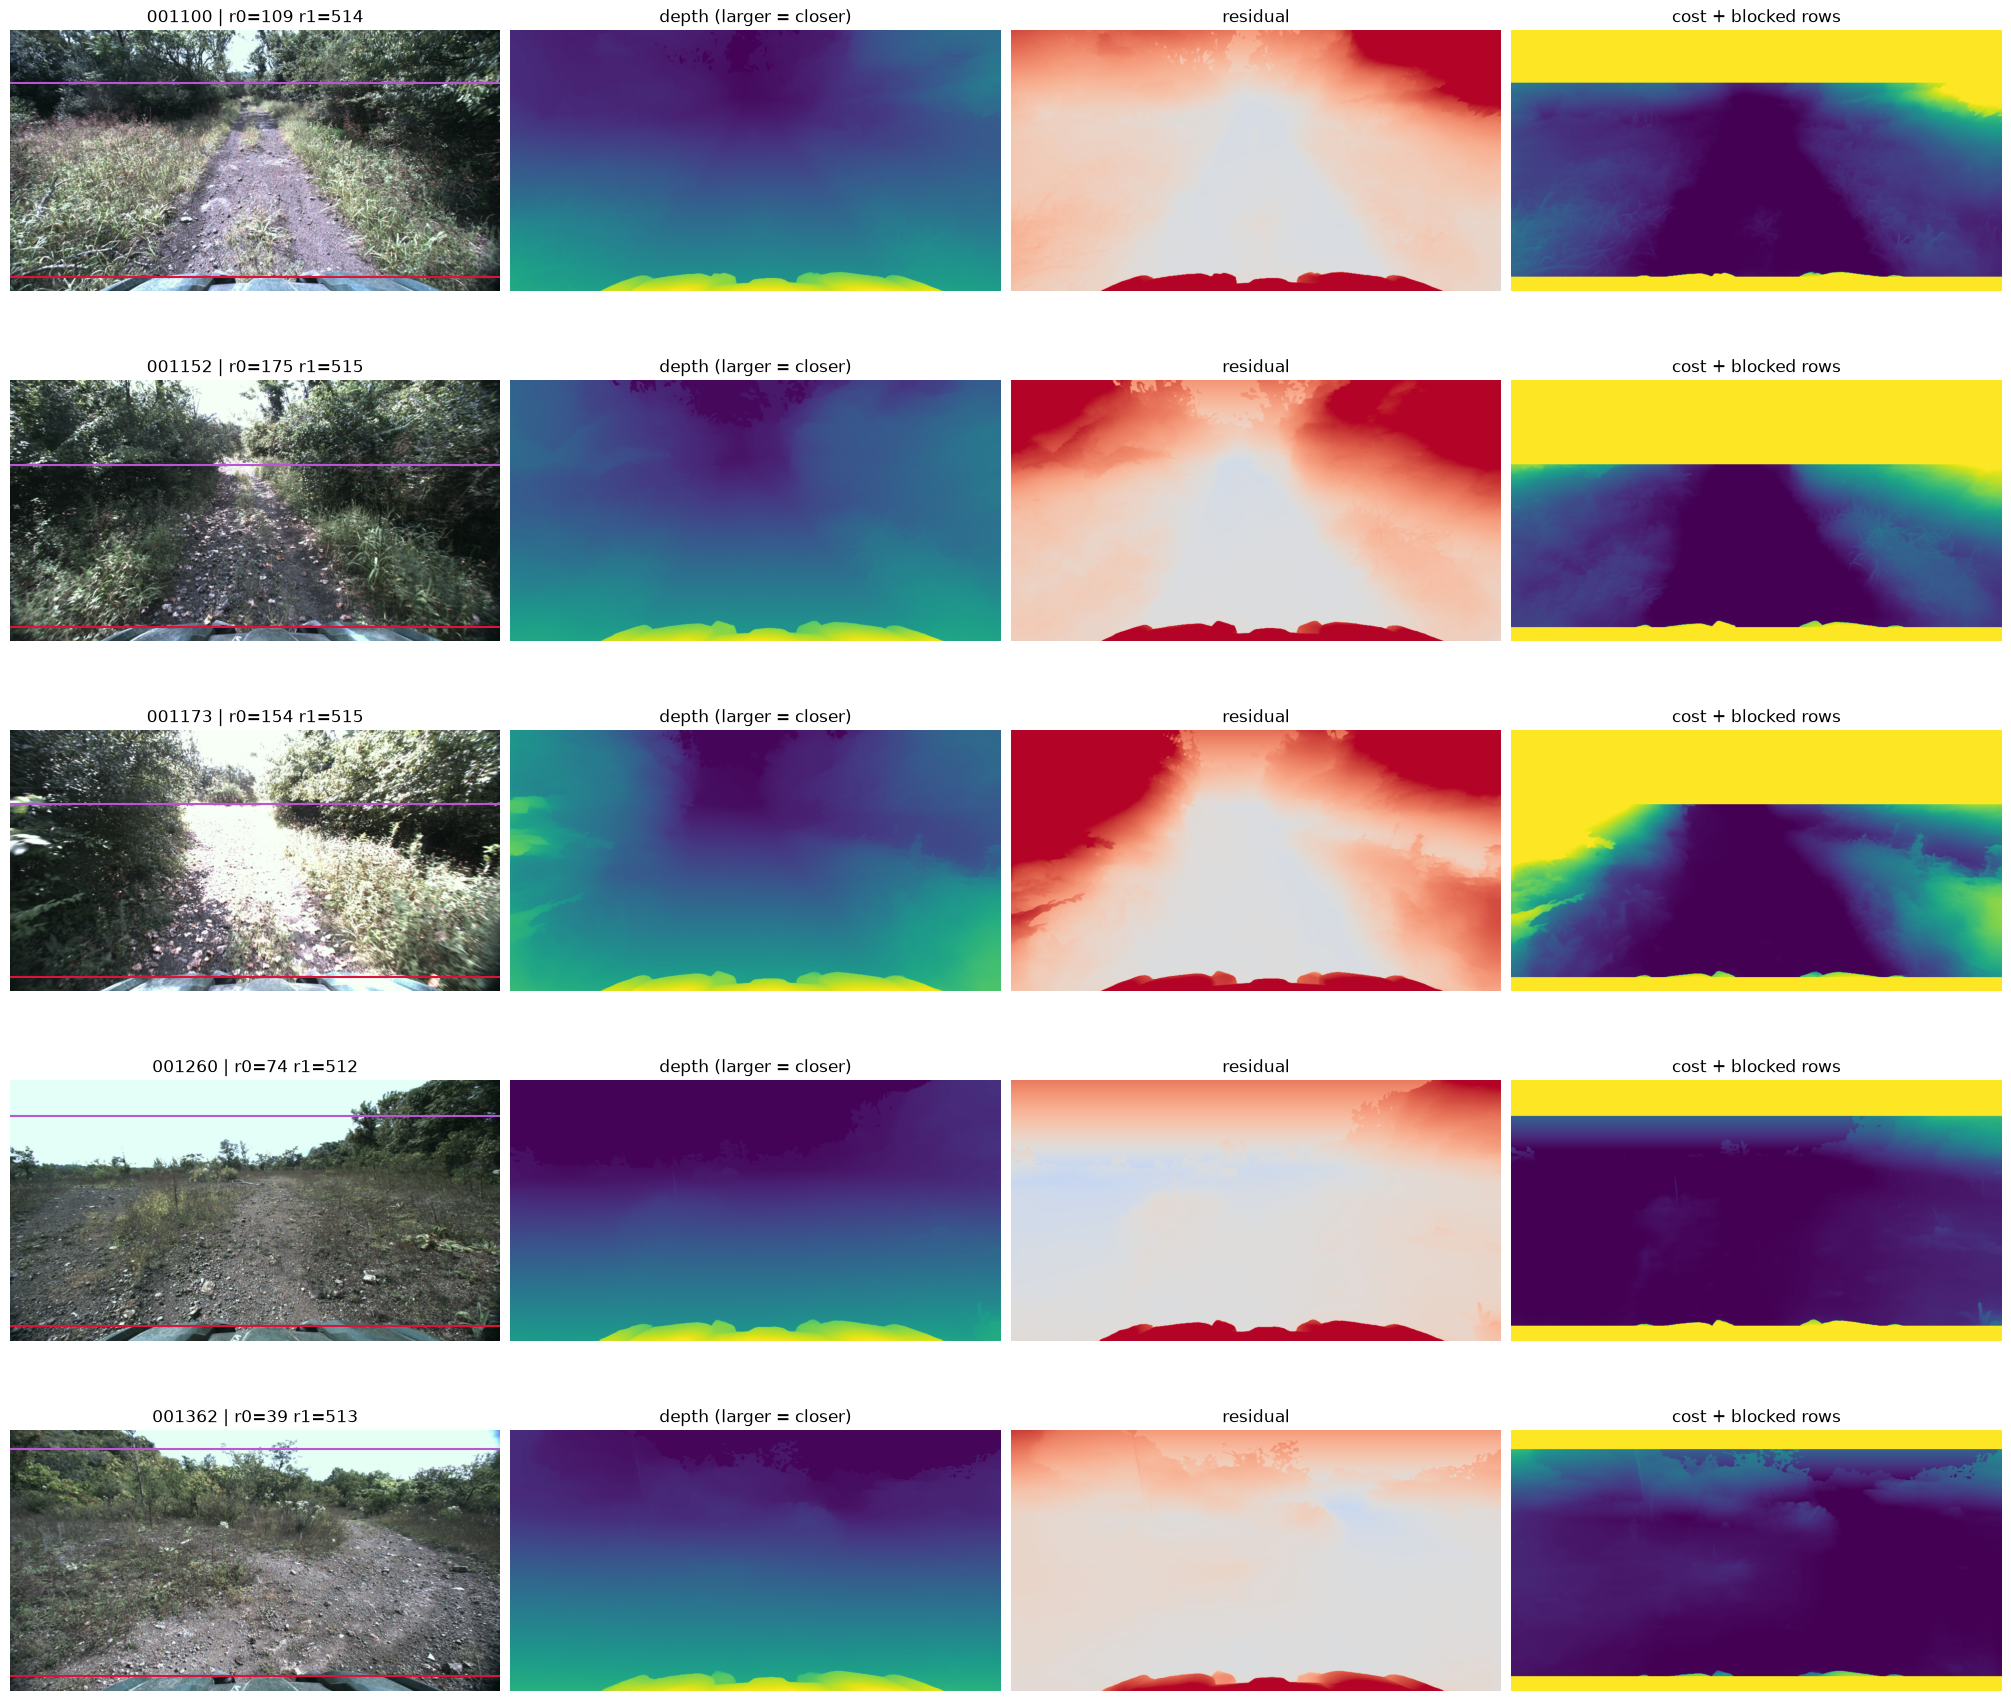

In [9]:
def show_frames(frames):
    """RGB with the usable rows, raw depth, residual and final cost of each frame in the list."""
    fig, axes = plt.subplots(len(frames), 4, figsize=(20, 3.5 * len(frames)), layout="constrained", squeeze=False) # squeeze=False: axes is always 2D, even with 1 frame
    for i, name in enumerate(frames):
        result = compute_costmap(load_norm(name), lo, hi, b)
        rgb = np.array(Image.open(index[name]["image"]))
        depth = np.load(DEPTH_DIR / name / "depth.npy")
        axes[i, 0].imshow(rgb)
        axes[i, 0].axhline(result["r0"], color="mediumorchid") # first usable row
        axes[i, 0].axhline(result["r1"], color="crimson") # last usable row
        axes[i, 0].set_title(f"{name} | r0={result['r0']} r1={result['r1']}")
        axes[i, 1].imshow(depth)
        axes[i, 1].set_title("depth (larger = closer)")
        axes[i, 2].imshow(result["residual"], vmin=-0.3, vmax=0.3, cmap="coolwarm")
        axes[i, 2].set_title("residual")
        axes[i, 3].imshow(result["cost_final"], vmin=0, vmax=1)
        axes[i, 3].set_title("cost + blocked rows")
        for ax in axes[i]:
            ax.axis("off")
    plt.show()
    plt.close(fig)

if SHOW_FRAMES:
    show_frames(SHOW_FRAMES)
else:
    print("SHOW_FRAMES is empty: no frame displayed")

## 6. Zip

The `outputs/` folder is zipped into `costmaps/<model>/geometric.zip`, with the folder inside the archive (`geometric.zip` contains `outputs/<frame>_geometric_cost.npy`). `run_info.json` stays outside of it.

In [ ]:
if MAKE_ZIP:
    zip_path = shutil.make_archive(str(OUT_DIR.parent), "zip", root_dir=OUT_DIR.parent, base_dir=OUT_DIR.name)   # creates costmaps/<model>/geometric.zip containing the folder outputs/
    print(zip_path, f"({Path(zip_path).stat().st_size / 1e6:.1f} MB)")
else:
    print("MAKE_ZIP is False: no zip made")

# Optional checks

Bellow you will find cells that can provide more explanation for certain aspects (fitiign the line), Nothing below is needed to produce the maps. Some cells use the maps that were produced above, and each one only needs the cells above it to have been run.

#### Research

The cells below show how the line fitting and the hood detection work on a few frames, and they were the part of the research that is easiest to see. They use `RESEARCH_DATASET` (BDD100K here) and not `DATASET`, so the maps above are not affected. The only requirement is that the depth of that dataset has already been computed with the same `MODEL`, by running sections 0 to 2 once with `DATASET = "bdd100k"`. Put the names of the frames you want to use in `RESEARCH_FRAMES`. 

In [33]:
RESEARCH_DATASET = "bdd100k" # dataset used in this section (its depth must exist for the same MODEL)
RESEARCH_FRAMES = [] # names of the frames to look at, if empty the first 3 frames that have a depth will be used
RESEARCH_IMAGES_DIR = DATA_DIR / RESEARCH_DATASET / "images"
RESEARCH_DEPTH_DIR = DATA_DIR / RESEARCH_DATASET / "depth" / MODEL
research_b = PARAMS[RESEARCH_DATASET]["b"] # block size of that dataset (only used to keep r0 inside the image)

def research_norm(name):
    return load_norm(name, depth_dir=RESEARCH_DEPTH_DIR) # normalized depth read from the research dataset

def research_rgb(name):
    for suffix in IMAGE_SUFFIXES: # the image can be .jpg or .png
        path = RESEARCH_IMAGES_DIR / f"{name}{suffix}"
        if path.exists():
            return np.array(Image.open(path).convert("RGB"))
    raise FileNotFoundError(f"no image called {name} in {RESEARCH_IMAGES_DIR}")

has_depth = sorted(p.parent.name for p in RESEARCH_DEPTH_DIR.glob("*/depth.npy")) # frames of the research dataset that have a depth
if not RESEARCH_FRAMES:
    RESEARCH_FRAMES = has_depth[:5] # default selection (see above)
research_frames = [n for n in RESEARCH_FRAMES if n in has_depth]
missing = [n for n in RESEARCH_FRAMES if n not in has_depth]
if missing:
    print(f"No depth in {RESEARCH_DEPTH_DIR} for {missing}.")
if not has_depth:
    print(f"No depth information was found. To get it: set DATASET = '{RESEARCH_DATASET}' in the config cell and run sections 0 to 2.")
print("Research frames:", research_frames)

Research frames: ['b1c9c847-3bda4659', 'b1cac6a7-04e33135', 'b1ceb32e-51852abe', 'b1d0091f-f2c2d2ae', 'b1d10d08-c35503b8']


#### Fitting the ground line

We used a code like the one below to determine why a straight line is a good model for the ground. On flat ground the depth value grows almost linearly with the image row (the lower a point is in the image, the closer it is). For each frame the pipeline fits a line on the ground and calculates what a ground pixel would have as value at each row. The residual is the measured value minus this line: close to 0 on the ground, positive when something is closer than the ground (a car, a bush), negative when it is farther.

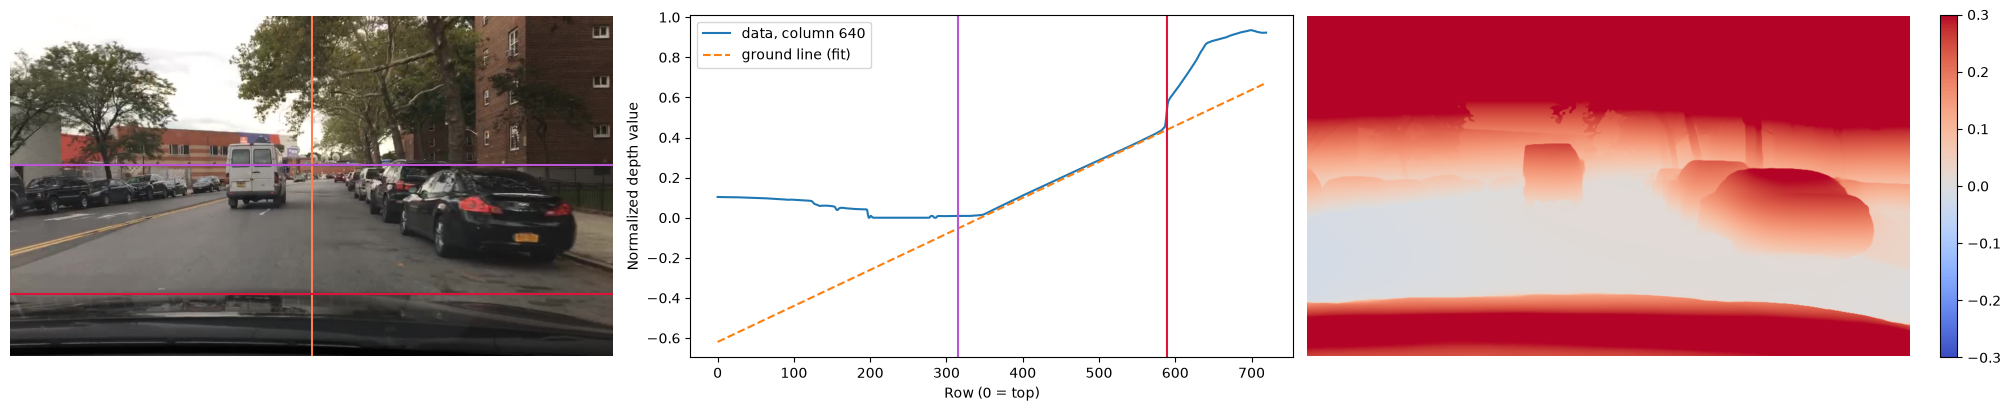

b1c9c847-3bda4659: horizon from the fitted line = 345, r0 = 315, r1 = 589


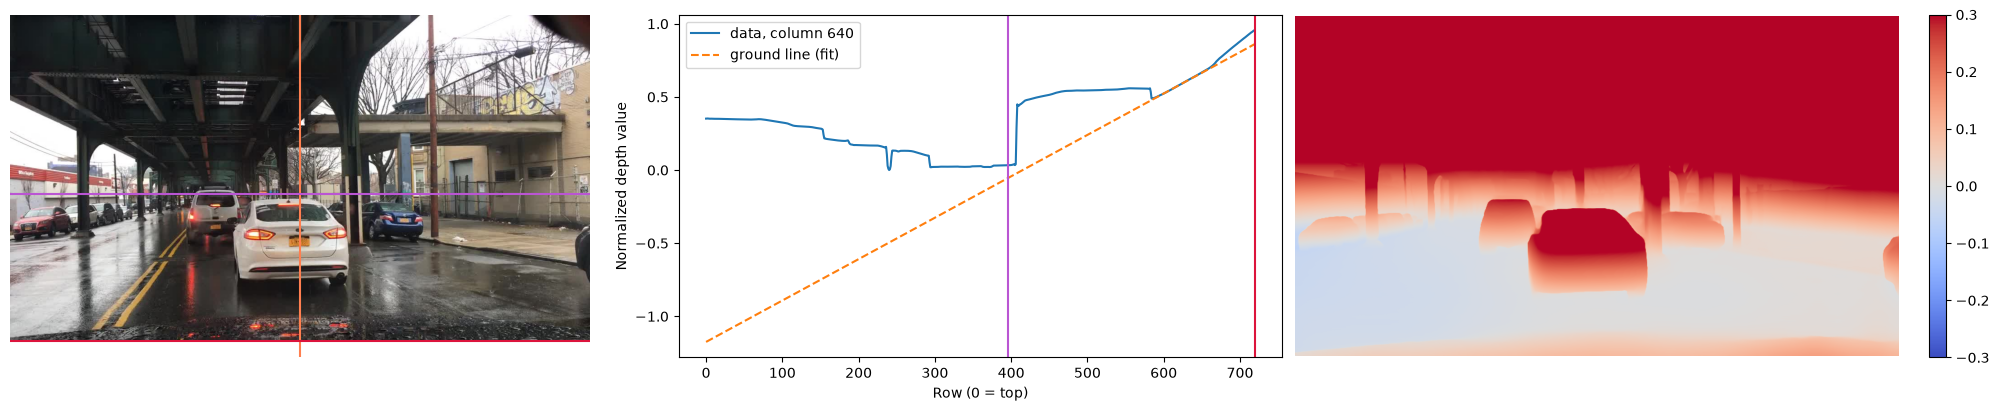

b1cac6a7-04e33135: horizon from the fitted line = 415, r0 = 396, r1 = 720


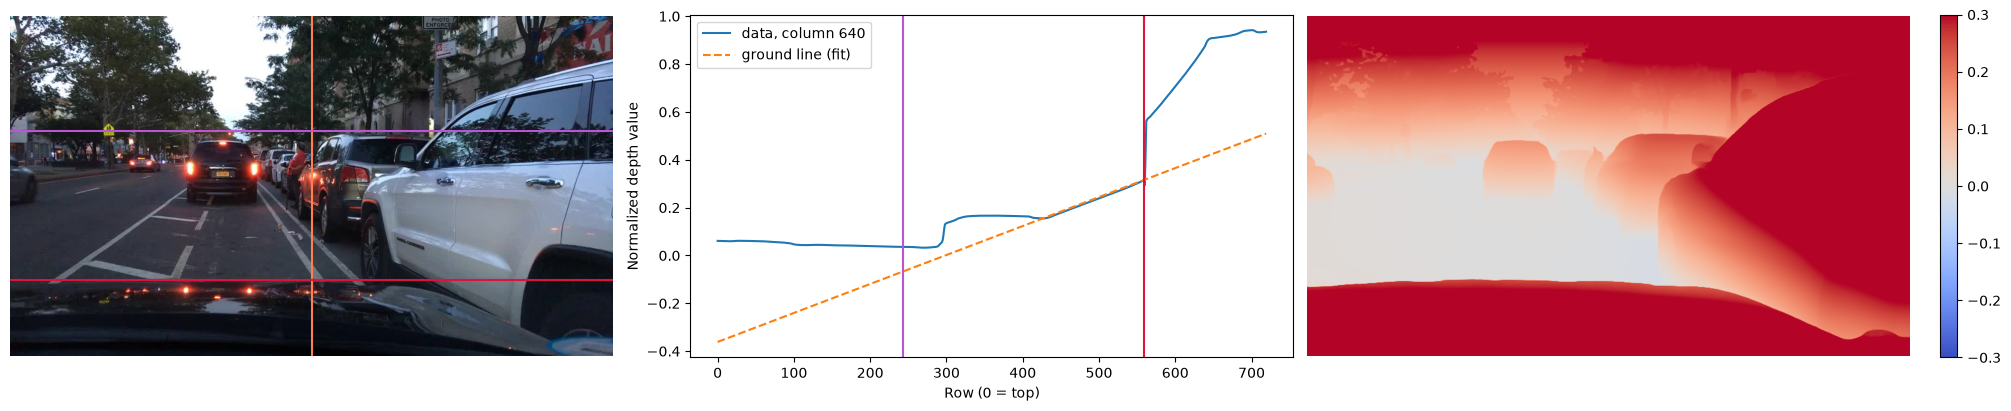

b1ceb32e-51852abe: horizon from the fitted line = 298, r0 = 243, r1 = 559


In [28]:
for name in research_frames:
    norm = research_norm(name)
    H, W = norm.shape
    col = W // 2 # the column we look at (the middle of the image)
    r1 = find_hood(norm)
    residual, coef, horizon = auto_residual(norm, r1) # coef = [slope, intercept] of the ground line
    r0 = int(np.clip(find_r0(residual, r1), 0, r1 - research_b))
    expected = np.polyval(coef, np.arange(H)) # value a ground pixel would have at each row (the line is continued above and below the fitted rows)

    fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(20, 4), layout="constrained")
    ax0.imshow(research_rgb(name))
    ax0.axvline(col, color="coral")
    ax0.axhline(r0, color="mediumorchid")
    ax0.axhline(r1, color="crimson")
    ax0.axis("off")

    ax1.plot(norm[:, col], label=f"data, column {col}")
    ax1.plot(expected, "--", label="ground line (fit)")
    ax1.axvline(r0, color="mediumorchid")
    ax1.axvline(r1, color="crimson")
    ax1.set_xlabel("Row (0 = top)")
    ax1.set_ylabel("Normalized depth value")
    ax1.legend()

    im = ax2.imshow(residual, vmin=-0.3, vmax=0.3, cmap="coolwarm") # ~0 = ground, positive = closer than the ground, negative = farther
    ax2.axis("off")
    fig.colorbar(im, ax=ax2)
    plt.show()
    plt.close(fig)
    print(f"{name}: horizon from the fitted line = {horizon:.0f}, r0 = {r0}, r1 = {r1}")

#### Finding the hood

This was used to find the row where the car's hood starts, so that it is left out of the fit and of the map. Going down the image, the ground gets closer and closer (the inverse depth rises slowly), but at the hood the value jumps up suddenly, because the hood is very close to the camera. We therefore look for the biggest upward jump in the lower part of the image (below `HOOD_TOP`) that is larger than `HOOD_JUMP`. Why do we use 3 columns ? Simply put, a single column is not always reliable. The hood is not always straight or centered in the image, so one column can fall beside it and see no jump. With three columns (at 25%, 50% and 75% of the width) we require at least `HOOD_MIN_AGREE` of them (2) to find an edge, and we keep the highest one. 

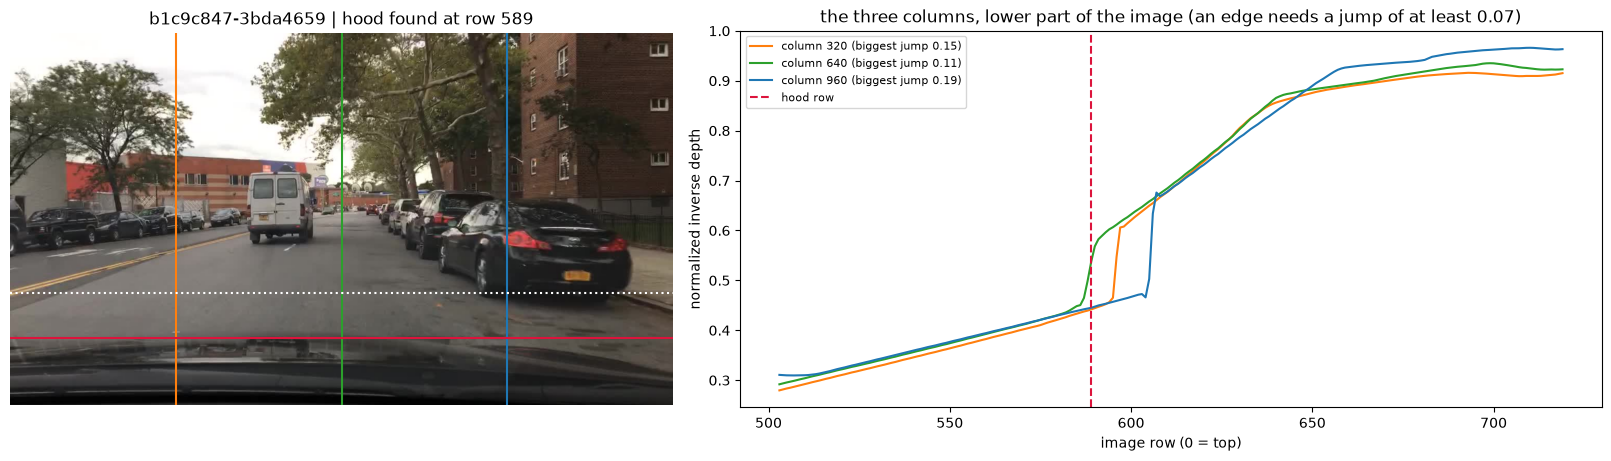

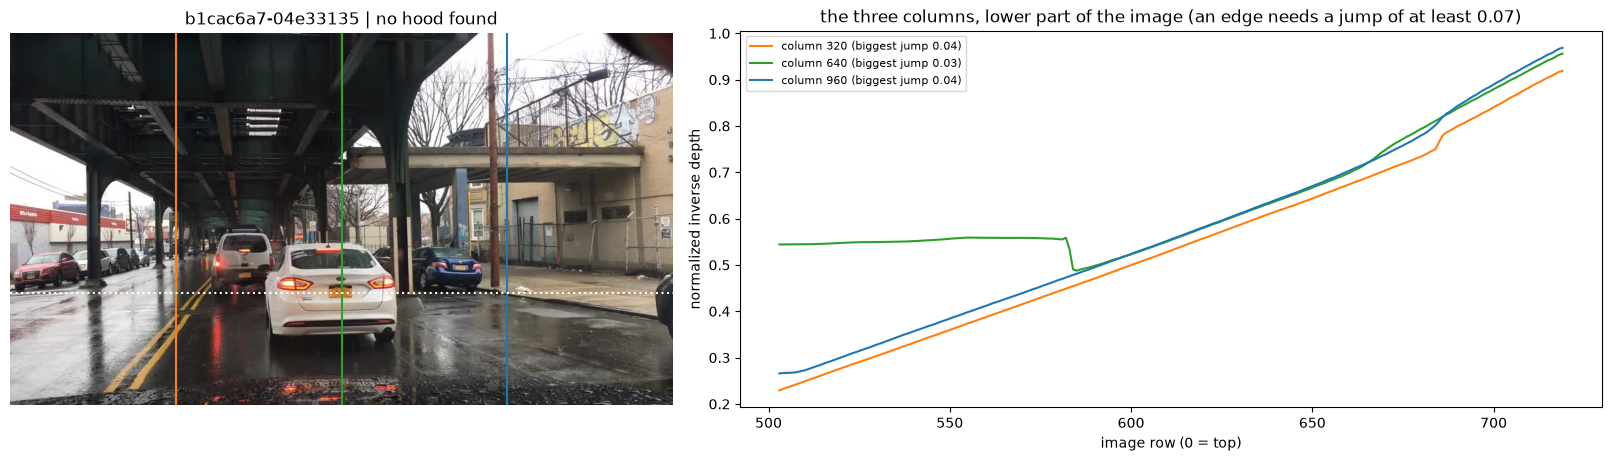

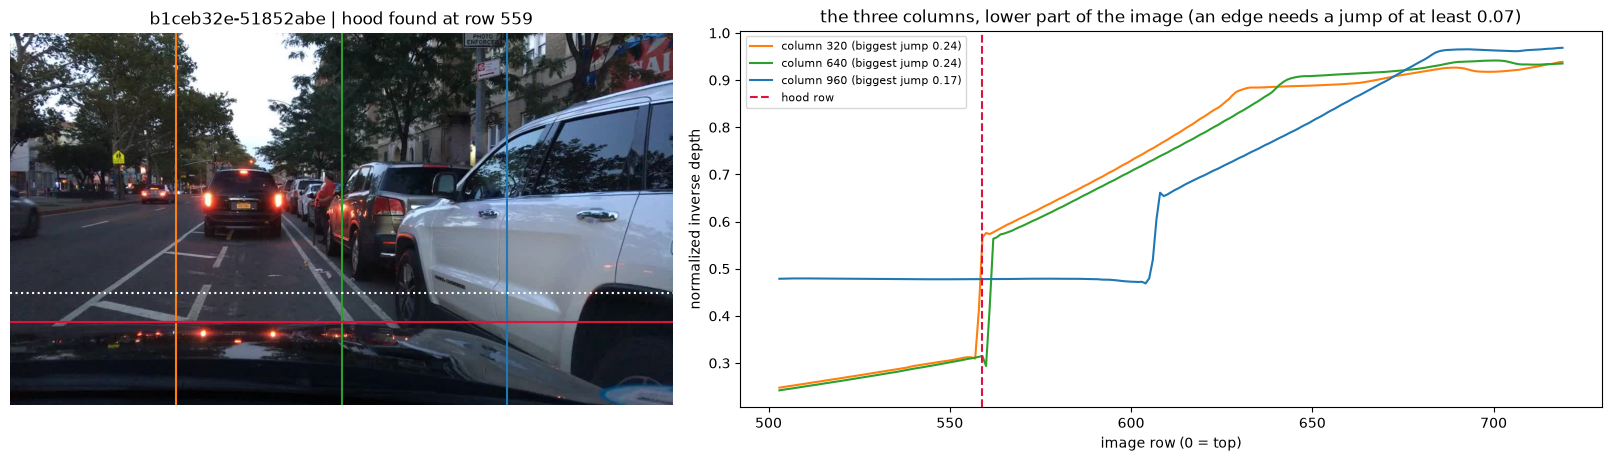

In [29]:
colors = ["tab:orange", "tab:green", "tab:blue"] # one color per column, the same in both panels
for name in research_frames:
    norm = research_norm(name)
    H, W = norm.shape
    hood = find_hood(norm) # H when no hood is found = bottom of the image
    top = int(HOOD_TOP * H) # the hood is only searched below this row
    cols = [int(c * W) for c in HOOD_COLS]

    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), layout="constrained", gridspec_kw={"width_ratios": [1, 1.3]})
    axes[0].imshow(research_rgb(name))
    for col, color in zip(cols, colors):
        axes[0].axvline(col, color=color) # where the three columns are in the image
    axes[0].axhline(top, color="white", linestyle=":") # start of the search zone
    if hood < H:
        axes[0].axhline(hood, color="crimson")
    axes[0].set_title(f"{name} | " + (f"hood found at row {hood}" if hood < H else "no hood found"))
    axes[0].axis("off")

    rows = np.arange(top, H)
    for col, color in zip(cols, colors):
        profile = norm[top:, col]
        ma = np.convolve(profile, np.ones(HOOD_K) / HOOD_K, mode="valid") # same moving average as in find_hood, repeated here only to print the jump
        step = ma[HOOD_K:] - ma[:-HOOD_K] # jump between two points HOOD_K rows apart
        axes[1].plot(rows, profile, color=color, label=f"column {col} (biggest jump {step.max():.2f})")
    if hood < H:
        axes[1].axvline(hood, color="crimson", linestyle="--", label="hood row")
    axes[1].set_xlabel("image row (0 = top)")
    axes[1].set_ylabel("normalized inverse depth")
    axes[1].set_title(f"the three columns, lower part of the image (an edge needs a jump of at least {HOOD_JUMP})")
    axes[1].legend(loc="upper left", fontsize=8)
    plt.show()
    plt.close(fig)

#### Clipping the negative values

We chose to clip the values in two places. This code cell explains why and how much of the image they affect. First, the raw depth of the model can contain small negative values (noise), which are set to 0 before the depth is divided by its own maximum. Second, after the ground line is subtracted, the residual can be negative where the ground is farther than the line predicts. Our model thus considers that negative pixels (in a hole for example) are not an obstacle... From what we observed on downhill sections in the datasets (rellis) this didn't impact it negatively so we stuck with this method. A residual above `hi` is clipped to cost 1, since it is already as bad as it can get. The table gives, for the rows between `r0` and `r1`, the share of pixels with a residual below `lo` (cost 0) and above `hi` (cost 1); the rest keeps an intermediate cost. It also gives the share of negative values in the raw depth, which should stay well below 1%. A large share on the left is not a problem by itself (it is mostly ground that follows the line). A large share in the middle or on the right means a lot of the zone is considered as not free.

*NB: based on the images you use to check the values the thresholds might feel off. However these are the values that worked best on all the frames we checked.*

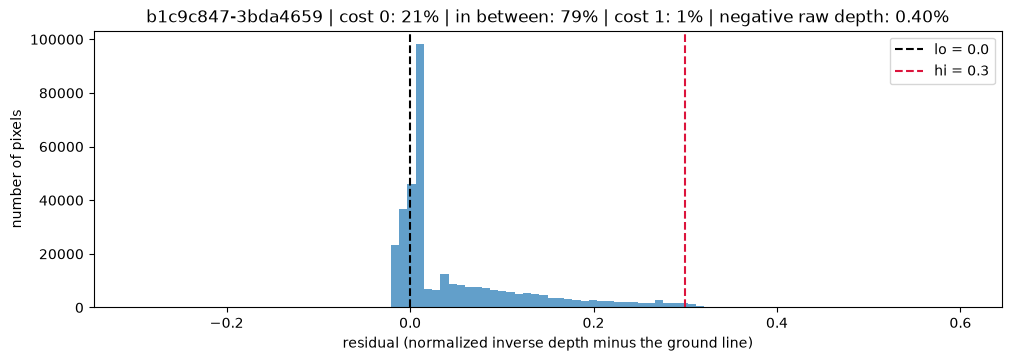

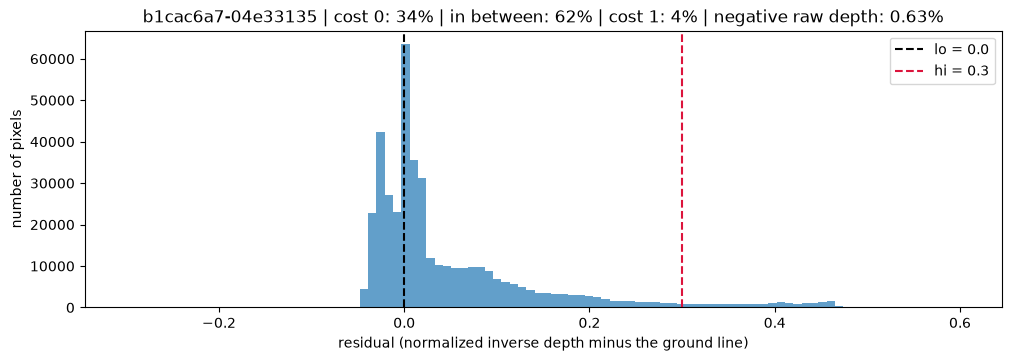

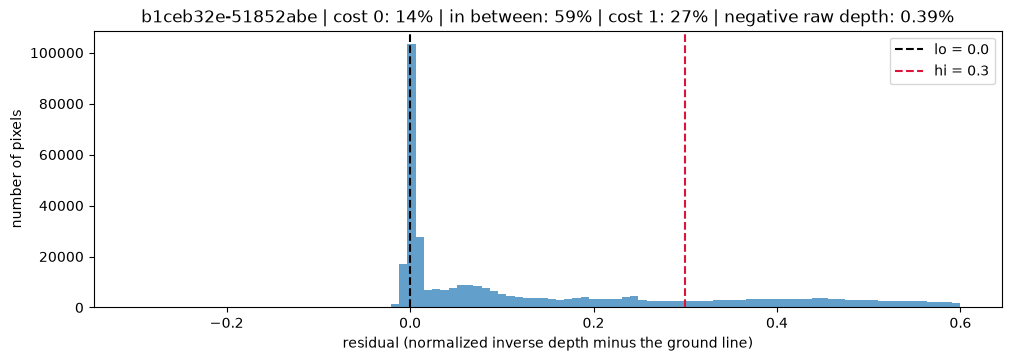

In [30]:
for name in research_frames:
    raw = np.load(RESEARCH_DEPTH_DIR / name / "depth.npy") # raw depth, before the clipping done in load_norm
    negative_depth = (raw < 0).mean() # share of pixels that load_norm sets to 0
    norm = research_norm(name)
    H, W = norm.shape
    r1 = find_hood(norm)
    residual, coef, horizon = auto_residual(norm, r1)
    r0 = int(np.clip(find_r0(residual, r1), 0, r1 - research_b))
    values = residual[r0:r1, :].ravel() # residual of the usable zone only
    below = (values < lo).mean() # cost 0 (ground, holes, downhill)
    above = (values > hi).mean() # cost 1 (clipped from above)
    between = 1 - below - above # intermediate cost

    fig, ax = plt.subplots(figsize=(10, 3.5), layout="constrained")
    ax.hist(values, bins=100, range=(-0.3, 0.6), color="tab:blue", alpha=0.7)
    ax.axvline(lo, color="k", linestyle="--", label=f"lo = {lo}")
    ax.axvline(hi, color="crimson", linestyle="--", label=f"hi = {hi}")
    ax.set_xlabel("residual (normalized inverse depth minus the ground line)")
    ax.set_ylabel("number of pixels")
    ax.set_title(f"{name} | cost 0: {below:.0%} | in between: {between:.0%} | cost 1: {above:.0%} | negative raw depth: {negative_depth:.2%}")
    ax.legend()
    plt.show()
    plt.close(fig)

#### What happens without limiting the rows

Here the same method is applied twice on the same frame. The first time the line is fitted on all rows down to the bottom of the image and the cost is computed on every row. The second time it is the normal pipeline, with the hood left out of the fit (`r1`) and the rows above the end of the ground (`r0`) set to cost 1. The hood is very close to the camera, so its values are much higher than the ground's. When the fit includes it, the line is pulled up, and the ground in front of the car gets a residual below the true one. Obstacles then look less high than they are, and the cost is too low where it matters most. On the other hand, the sky and far terrain are not ground, so the line has nothing to say about them. Without `r0` they get a cost that comes from the line and not from the scene. This is why those rows are set to 1: we do not know what is there, so the planner should not go there.

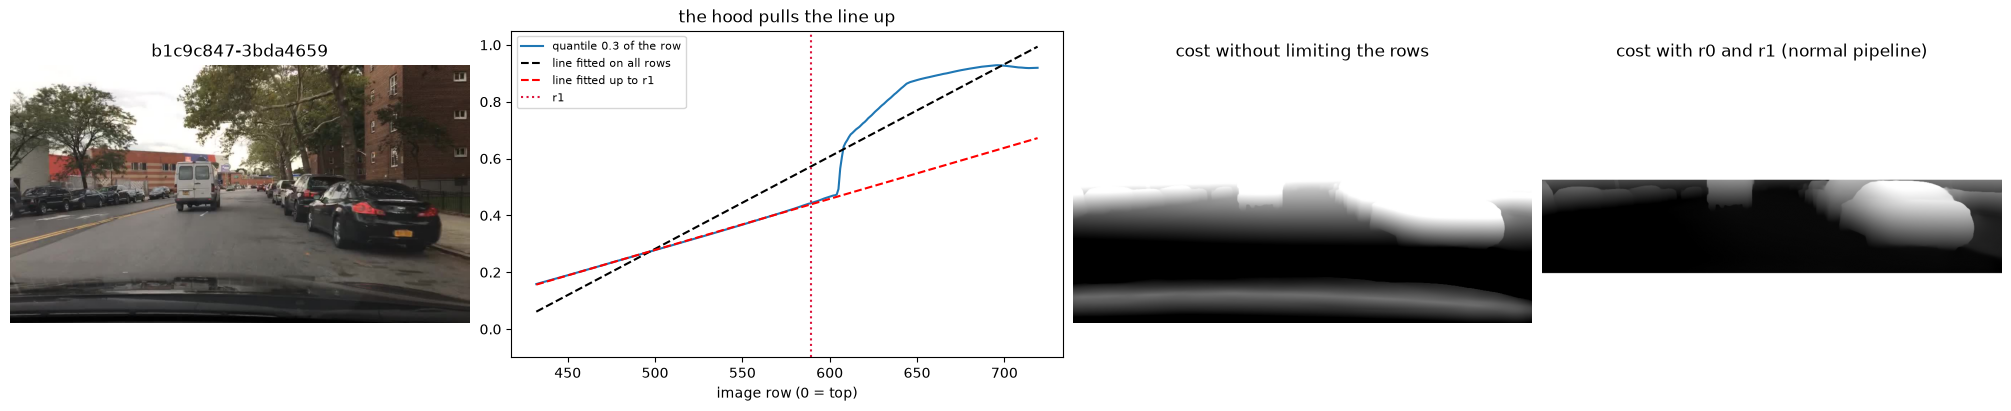

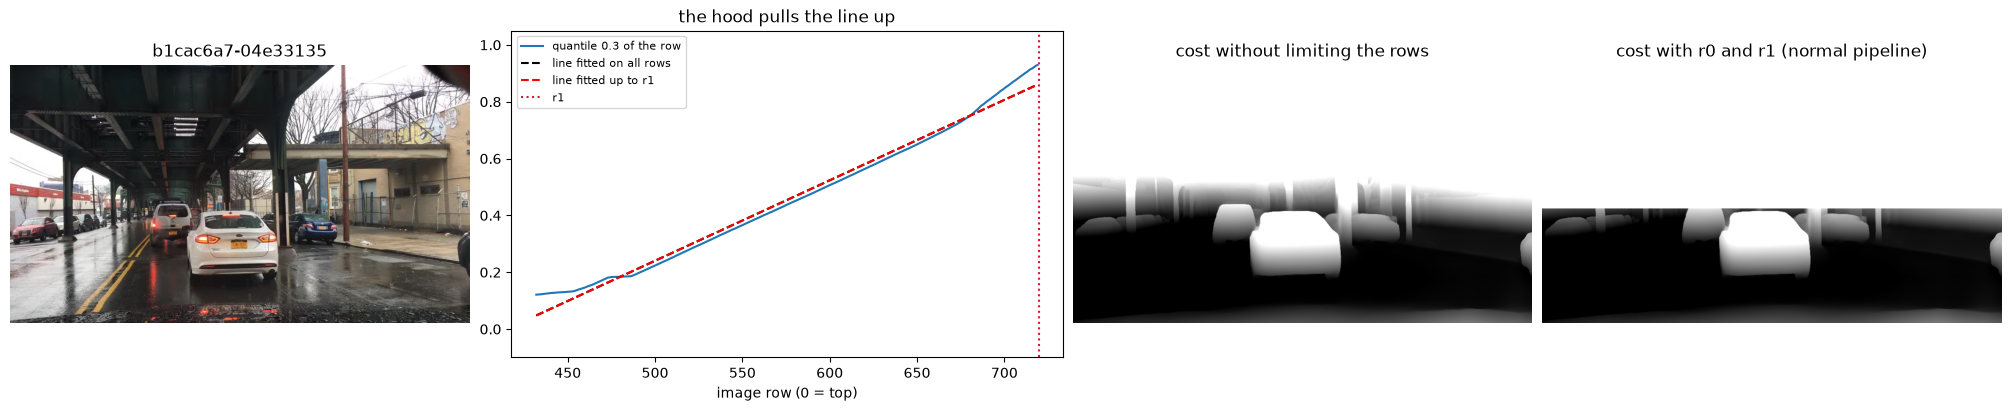

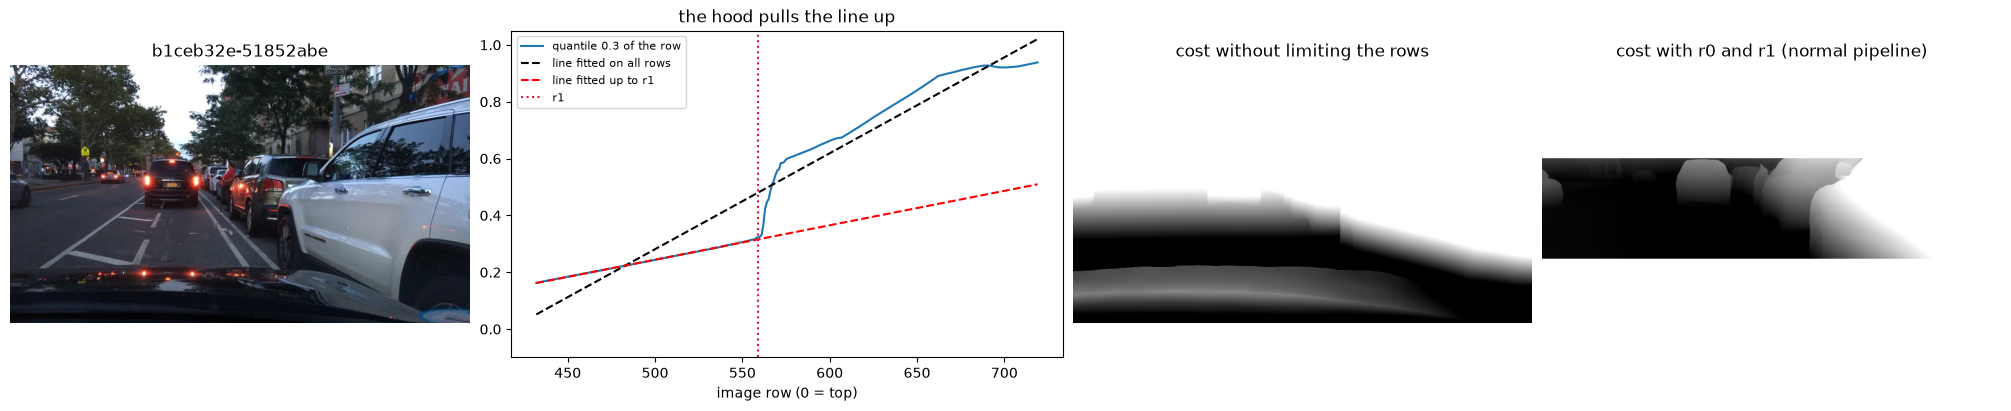

In [32]:
for name in research_frames:
    norm = research_norm(name)
    H, W = norm.shape
    top = int(FIT_TOP * H)

    res_free, coef_free, hor_free = auto_residual(norm, H) # same fit, but r1 = H: the hood is not left out
    cost_free = np.clip((res_free - lo) / (hi - lo), 0, 1) # cost on every row, no r0 and no r1
    result = compute_costmap(norm, lo, hi, b) # the normal pipeline, with r0 and r1
    cost_limited = result["cost_final"]
    coef_limited = np.polyfit(np.arange(top, result["r1"]), np.quantile(norm[top:result["r1"], :], Q_FIT, axis=1), 1) # the line of the normal pipeline

    q_fit = np.quantile(norm[top:, :], Q_FIT, axis=1) # the values the unlimited fit is made on
    rows = np.arange(top, H)

    fig, axes = plt.subplots(1, 4, figsize=(20, 4), layout="constrained", gridspec_kw={"width_ratios": [1, 1.2, 1, 1]})
    axes[0].imshow(research_rgb(name))
    axes[0].set_title(name)
    axes[0].axis("off")
    axes[1].plot(rows, q_fit, label=f"quantile {Q_FIT} of the row")
    axes[1].plot(rows, np.polyval(coef_free, rows), "k--", label="line fitted on all rows")
    axes[1].plot(rows, np.polyval(coef_limited, rows), "r--", label="line fitted up to r1")
    axes[1].axvline(result["r1"], color="crimson", linestyle=":", label="r1")
    axes[1].set_ylim(-0.1, 1.05)
    axes[1].set_xlabel("image row (0 = top)")
    axes[1].set_title("the hood pulls the line up")
    axes[1].legend(loc="upper left", fontsize=8)
    axes[2].imshow(cost_free, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title("cost without limiting the rows")
    axes[2].axis("off")
    axes[3].imshow(cost_limited, cmap="gray", vmin=0, vmax=1)
    axes[3].set_title("cost with r0 and r1 (normal pipeline)")
    axes[3].axis("off")
    plt.show()
    plt.close(fig)

#### Stability between neighbouring frames

If the frames are consecutive, the rows `r0` and `r1` found by the pipeline should change slowly from one frame to the next. This prints them for the first 20 frames (the range and the biggest jump over the whole dataset were printed at the end of section 4).

In [ ]:
with open(OUT_DIR.parent / "run_info.json") as f:
    frames_info = json.load(f)["frames"]
for name in list(frames_info)[:20]:
    fi = frames_info[name]
    print(name, "r0", fi["r0"], "r1", fi["r1"], "horizon", round(fi["horizon"]))

#### Size of a map and number of distinct values

Why the rounding is needed: the compressed size (zlib is the compression the zip uses) of one map as it is computed, rounded to `DECIMALS` decimals, and in float16. The number of distinct values and the most common ones show how the costs are spread (for example how many pixels are exactly 0 or exactly 1).

In [ ]:
import zlib

files = sorted(OUT_DIR.glob(f"*{SUFFIX}.npy"))
name = files[len(files) // 2].stem.removesuffix(SUFFIX)
result = compute_costmap(load_norm(name), lo, hi, b) # recomputed here, because the saved map is already rounded
cost = result["cost_final"].astype(np.float32)
print(name, "| distinct values before rounding:", len(np.unique(cost)))
for label, arr in [("float32", cost), (f"float32 rounded to {DECIMALS} decimals", np.round(cost, DECIMALS)), ("float16", cost.astype(np.float16))]:
    print(label, "->", round(len(zlib.compress(arr.tobytes())) / 1e6, 3), "MB")

rounded = np.round(cost, DECIMALS)
values, counts = np.unique(rounded, return_counts=True) # each distinct value and how many pixels have it
print("distinct values after rounding:", len(values))
for i in np.argsort(counts)[::-1][:10]: # most common values first
    print(values[i], round(100 * counts[i] / rounded.size, 1), "% of pixels")

# Manual baseline (optional)

Before the automatic version, the ground line was fitted on one column picked by hand (`col_road`), between two rows picked by hand (`r0` and `r1`). This part keeps that version as a baseline, to compare the automatic pipeline with. It needs manual values for some frames of the dataset (`SETTINGS` below, only filled for BDD100K and RELLIS-3D).

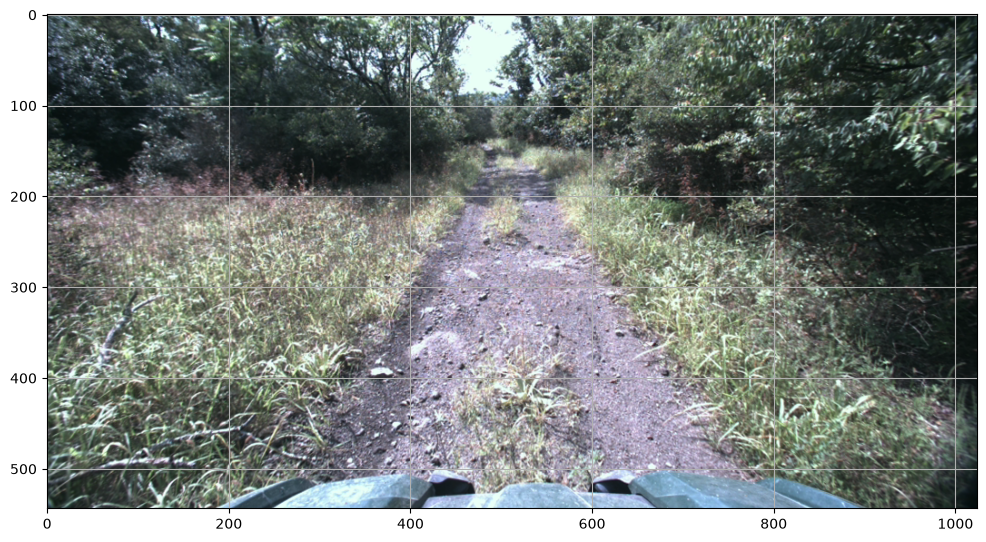

In [10]:
SETTINGS = { # (row 0 is the top of the image)
    "bdd100k": {
        "b1c9c847-3bda4659": {"col_road": 640, "r0": 350, "r1": 560},
        "b1cac6a7-04e33135": {"col_road": 350, "r0": 400, "r1": 650},
        "b1ceb32e-51852abe": {"col_road": 350, "r0": 260, "r1": 550},
        "b1d0091f-f2c2d2ae": {"col_road": 900, "r0": 350, "r1": 660},
        "b1d10d08-c35503b8": {"col_road": 640, "r0": 300, "r1": 630},
    },
    "rellis": {
        "frame000164-1581624669_149": {"col_road": 1450, "r0": 450, "r1": 1200},
        "frame000344-1581623824_749": {"col_road": 1100, "r0": 400, "r1": 1200},
        "frame000928-1581623883_149": {"col_road": 750, "r0": 580, "r1": 1200},
        "frame002765-1581797426_909": {"col_road": 750, "r0": 50, "r1": 1200},
        "frame003557-1581797506_109": {"col_road": 900, "r0": 640, "r1": 1100},
    },
}

name = names[0] # choose the frame to display
rgb = np.array(Image.open(index[name]["image"]))
plt.figure(figsize=(12, 7))
plt.imshow(rgb)
plt.grid(True)
plt.show()

## Manual version against automatic version

`road_residual` is the manual version of the ground line: a straight line fitted on one column between `r0` and `r1`. For each frame of `SETTINGS`, both pipelines are run and compared on the rows that both consider usable: the mean absolute difference between the two cost maps, and the share of pixels where they differ by more than 0.2.

In [ ]:
def road_residual(norm, col_road, r0, r1):
    """MANUAL version: fit a line (value vs row) on ONE column between r0 and r1 and subtract it from every pixel."""
    rows = np.arange(r0, r1)
    coef = np.polyfit(rows, norm[r0:r1, col_road], deg=1) # return [slope, intercept]
    expected = np.polyval(coef, np.arange(norm.shape[0])) # road value at each row, shape (H,)
    residual = norm - expected[:, None] # (H, 1) broadcast across all columns
    return residual, coef


manual_frames = {n: s for n, s in SETTINGS.get(DATASET, {}).items() if n in index} # only the frames that have manual values and a depth
if not manual_frames:
    print(f"no manual values for the frames of '{DATASET}' in SETTINGS: nothing to compare")
for name, s in manual_frames.items():
    norm = load_norm(name)
    auto = compute_costmap(norm, lo, hi, b) # automatic pipeline
    residual, coef = road_residual(norm, s["col_road"], s["r0"], s["r1"])
    manual = finish_costmap(residual, s["r0"], s["r1"], lo, hi, b) # same steps with the manual rows
    rows = slice(max(auto["r0"], s["r0"]), min(auto["r1"], s["r1"])) # rows usable in both versions
    diff = np.abs(manual["cost_final"][rows] - auto["cost_final"][rows])
    print(name[:12], "| mean diff", round(float(diff.mean()), 3), "| pixels differing by more than 0.2:", round(100 * float((diff > 0.2).mean()), 1), "%")

no manual values for the frames of 'tartandrive_2' in SETTINGS: nothing to compare
